# Chapter 10 - Neural Learning about Edges and Corners: Intro to Convolutional Neural Networks

## Summary
Fully connected layers ignore image structure and re-learn the same feature at every position. **Convolutional layers** reuse a small set of weights across the image.
- **Reusing weights:** a small **kernel** (e.g. 3x3) slides over the image; the same weights detect the same feature (edge/corner) anywhere = **translation invariance** and far fewer parameters.
- **Convolution:** at each position take the dot product of the kernel with the patch it covers, producing a *feature map*.
- Several kernels -> several feature maps, each detecting a different pattern (**filters**).
- Feature maps are flattened and fed into a normal dense layer for the final classification.
- Result: better accuracy and generalisation than a dense network on images.

## Theory
- **Local connectivity:** each output unit sees only a small receptive field.
- **Weight sharing:** same kernel at every location; parameters = `k*k*num_kernels` rather than `pixels*hidden`.
- **Output size:** `(H-k+1) x (W-k+1)` with stride 1 and no padding.
- **Stacking:** deeper conv layers combine edges into corners, shapes and objects.
- **Backprop:** gradients for a kernel are summed over every position where it was applied.

In [1]:
# If numpy / scikit-learn are missing in this kernel, uncomment:
# %pip install numpy scikit-learn
import numpy as np

In [2]:
# Dataset: scikit-learn's bundled 8x8 handwritten digits (offline stand-in for MNIST's 28x28).
# The code is identical in spirit; only image size differs. Swap in MNIST if you like.
from sklearn.datasets import load_digits
digits = load_digits()
X = digits.data / 16.0                      # pixels scaled to 0..1
y = digits.target
labels = np.eye(10)[y]                      # one-hot
n_train = 1000
images, train_labels = X[:n_train], labels[:n_train]
test_images, test_labels = X[n_train:], labels[n_train:]
print(images.shape, test_images.shape)

(1000, 64) (797, 64)


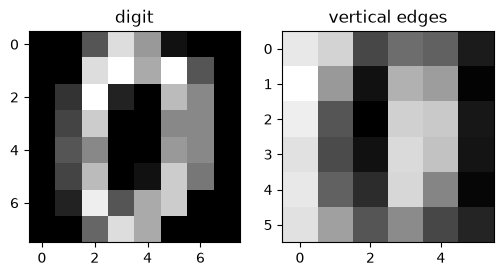

In [3]:
# Manual convolution: a 3x3 vertical-edge kernel on one digit
import matplotlib.pyplot as plt
img = images[0].reshape(8, 8)
kernel = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], float)
def conv2d(im, k):
    kh, kw = k.shape
    out = np.zeros((im.shape[0]-kh+1, im.shape[1]-kw+1))
    for r in range(out.shape[0]):
        for c in range(out.shape[1]):
            out[r, c] = (im[r:r+kh, c:c+kw] * k).sum()
    return out
fm = conv2d(img, kernel)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("digit")
ax[1].imshow(fm, cmap="gray"); ax[1].set_title("vertical edges")
plt.show()

In [4]:
# Conv network from the book: 3x3 kernels -> flatten -> dense softmax
tanh = np.tanh
tanh2deriv = lambda o: 1 - o ** 2
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True)); return e / e.sum(axis=1, keepdims=True)

def get_patches(batch, k=3):
    # batch: (B,8,8) -> (B*positions, k*k) one row per sliding window
    B, H, W = batch.shape
    rows = []
    for r in range(H - k + 1):
        for c in range(W - k + 1):
            rows.append(batch[:, r:r+k, c:c+k].reshape(B, 1, k*k))
    return np.concatenate(rows, axis=1)       # (B, positions, 9)

np.random.seed(1)
alpha, batch_size, iters = 2.0, 128, 60
k, num_kernels = 3, 8
H = 8; out_dim = (H - k + 1)                  # 6
positions = out_dim * out_dim                 # 36
kernels = 0.02 * np.random.random((k*k, num_kernels)) - 0.01
w_dense = 0.2 * np.random.random((positions * num_kernels, 10)) - 0.1

def forward(batch):
    patches = get_patches(batch.reshape(-1, 8, 8))              # (B,36,9)
    B = patches.shape[0]
    conv = patches.reshape(B * positions, k*k).dot(kernels)     # (B*36, K)
    conv_out = conv.reshape(B, positions * num_kernels)
    return patches, conv_out

for j in range(iters):
    correct = 0
    for i in range(len(images) // batch_size):
        s, e = i * batch_size, (i + 1) * batch_size
        l0 = images[s:e]
        patches, l1_lin = forward(l0)
        l1 = tanh(l1_lin)
        l2 = softmax(l1.dot(w_dense))
        B = l0.shape[0]
        correct += np.sum(np.argmax(l2, 1) == np.argmax(train_labels[s:e], 1))
        d2 = (train_labels[s:e] - l2) / (B * B)
        d1 = d2.dot(w_dense.T) * tanh2deriv(l1)
        w_dense += alpha * l1.T.dot(d2)
        # gradient for the shared kernels = sum over all positions
        d1_flat = d1.reshape(B * positions, num_kernels)
        kernels += alpha * patches.reshape(B * positions, k*k).T.dot(d1_flat)
    if j % 10 == 0 or j == iters - 1:
        _, tl = forward(test_images)
        pt = softmax(tanh(tl).dot(w_dense))
        print(f"I:{j:3d} Train-Acc:{correct/(len(images)//batch_size*batch_size):.3f} "
              f"Test-Acc:{np.mean(np.argmax(pt,1)==np.argmax(test_labels,1)):.3f}")

I:  0 Train-Acc:0.141 Test-Acc:0.217
I: 10 Train-Acc:0.340 Test-Acc:0.364
I: 20 Train-Acc:0.550 Test-Acc:0.555
I: 30 Train-Acc:0.711 Test-Acc:0.704
I: 40 Train-Acc:0.834 Test-Acc:0.790
I: 50 Train-Acc:0.882 Test-Acc:0.841
I: 59 Train-Acc:0.903 Test-Acc:0.863


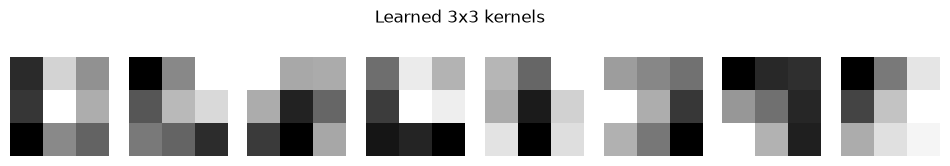

In [5]:
# Visualise learned kernels
fig, ax = plt.subplots(1, num_kernels, figsize=(12, 2))
for i in range(num_kernels):
    ax[i].imshow(kernels[:, i].reshape(3, 3), cmap="gray"); ax[i].axis("off")
plt.suptitle("Learned 3x3 kernels"); plt.show()

## Takeaways
Convolution reuses a few small weight patterns across the image, giving fewer parameters and features that are learned once and found everywhere. This is the base of modern computer vision.